# Assay-type text embeddings

A dense, semantic representation of *how* a degradation value was measured (Western blot, HiBiT, HTRF, ...), cached next to the
other TACK embeddings so it can replace or complement the one-hot `assay` block of `fusion_comparison.ipynb`.

The assay types are collected from every CSV in `data/yaochen/`, **canonised** with two complementary rule sets, described by
**N = 3 short hand-written sentences each**, embedded with a sentence transformer, and **mean-pooled** into one vector per assay
type.

| section | content |
|---|---|
| 1 | Canonisation: a *closed* vocabulary (14 fixed types) and an *open* one (finer, data-driven), both with `unknown` |
| 2 | Three descriptions per canonical assay |
| 3 | Sentence-transformer embeddings and pooling (3 sentences -> 1 vector) |
| 4 | PCA compression: how many dimensions are enough? |
| 5 | Cache files (`TACKAI_CACHE`) |
| 6 | `embed_assays()`: lookup with an on-the-fly fallback for assays never seen |
| 7 | Similarity matrices of the canonical assay types |
| 8 | Summary and how to load the cache |

Every section ends with a test cell (plain `assert`s, printing `OK`); the notebook runs top to bottom with no manual steps.

## Setup

In [2]:
import os, sys, json, re, unicodedata, warnings
from pathlib import Path

# macOS: torch and xgboost each bundle their own libomp; multi-threaded use of both in one process segfaults. Set this before
# numpy/torch are imported, i.e. run this cell first in a fresh kernel.
if sys.platform == "darwin":
    os.environ.setdefault("OMP_NUM_THREADS", "1")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import linkage, leaves_list, optimal_leaf_ordering
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer, models as st_models
from dotenv import load_dotenv, find_dotenv

from tackai.data.utils import get_cache_dir
from tackai.data.embeddings.utils import EmbeddingMixin

warnings.filterwarnings("ignore", category=FutureWarning)
load_dotenv(find_dotenv())  # picks up TACKAI_CACHE from .env when present; otherwise ~/.cache/tackai

# ----- configuration -------------------------------------------------------------------------------------------------
MODEL_NAME = "sentence-transformers/all-mpnet-base-v1"   # same encoder as the cell-line embeddings
MODEL_TAG = MODEL_NAME.split("/")[-1]
N_DESCRIPTIONS = 3        # short descriptions written per canonical assay
PCA_DIMS = 8              # size of the compressed embedding that is cached next to the full one
ASSAY_COLUMNS = ["Assay", "Assay_STD"]   # Assay_STD is the upstream (coarser) standardisation of Assay

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "yaochen").is_dir())
DATA_DIR = ROOT / "data" / "yaochen"
OUT_DIR = ROOT / "notebooks" / "assay_embedding_results"
OUT_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path(get_cache_dir())
print(f"data: {DATA_DIR}\nfigures: {OUT_DIR}\ncache: {CACHE_DIR}")

/Users/ribes/phd/TACK/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/jd/c3ktk08x3cj7ck0516xnxrvm0000gn/T/ipykernel_60288/3054144081.py:17: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import SentenceTransformer, models as st_models


data: /Users/ribes/phd/TACK/data/yaochen
figures: /Users/ribes/phd/TACK/notebooks/assay_embedding_results
cache: /Users/ribes/.cache/tackai


## 1. Canonisation

Raw assay strings are free text (about 100 distinct spellings in the CSVs: "Western Blot", "immunoblotting (Western blot)", "Licor-quantification of Western blots", ...).
Two rule sets map them to canonical types:

* **closed** (`canonical_assay`): a fixed vocabulary of 14 types, ordered regex rules, first match wins, anything unmatched is `other`.
  Because the vocabulary is fixed, an embedding table keyed on it is always complete, and it is a drop-in semantic replacement for the one-hot `assay` block.
* **open** (`normalize_assay`): finer, keyword rules; text no rule recognises is passed through (normalised) as its own type, so the vocabulary
  is whatever the data contains. Reporter, biosensor and viability assays stay separate instead of collapsing into `other`.

Both map a missing value to the same key, **`unknown`** (the open rule set originally called it `missing`; renamed so the two tables share the key).
`unknown` is not a corner case: it is the *most common* "assay" when the overlapping CSVs are pooled (60 % of the `Assay` rows; 38 % in `TACKv2.csv`, up to 98 % in other files; per-file shares below).

The vocabularies are collected from **both** `Assay` and `Assay_STD`, so no type reported anywhere in the CSVs is missed; the row counts shown later are from `Assay` only
(the column `fusion_comparison.ipynb` consumes), so `Assay_STD` rows are not counted twice.

### 1.1 Closed vocabulary (14 types)

In [4]:
ASSAY_VOCAB = ["western_blot", "in_cell_western", "capillary_immunoassay", "hibit", "nanoluc_reporter", "htrf",
               "elisa", "msd", "flow_cytometry", "high_content", "imaging", "mass_spec", "other", "unknown"]
# ordered: the first matching rule wins
_ASSAY_RULES = [("in_cell_western", r"in[- ]?cell western|incell western|in-cell elisa|cytoblot"),
                ("capillary_immunoassay", r"capillary|simple western|jess|\bwes\b"),
                ("hibit", r"hibit"),
                ("nanoluc_reporter", r"nanoluc|nano-glo|luciferase|luminescen"),
                ("htrf", r"htrf"),
                ("flow_cytometry", r"flow cytometry|facs"),
                ("high_content", r"high[- ]content|operetta|incell hunter"),
                ("western_blot", r"western|immunoblot|dot blot|licor"),
                ("elisa", r"elisa"),
                ("msd", r"\bmsd\b"),
                ("imaging", r"immunofluorescence|imaging|microscop"),
                ("mass_spec", r"mass spec|proteomic|lc-ms")]

def _missing(v):
    return v is None or (isinstance(v, float) and np.isnan(v)) or (isinstance(v, str) and not v.strip())

def canonical_assay(raw):
    """Map free-text assay descriptions to a category of ``ASSAY_VOCAB`` (first matching rule wins)."""
    if _missing(raw):
        return "unknown"
    s = str(raw).strip().lower()
    return next((name for name, pat in _ASSAY_RULES if re.search(pat, s)), "other")

### 1.2 Open vocabulary (data-driven)

In [5]:
def normalize_assay(value) -> str:
    """Normalise a raw assay string to a finer, open-vocabulary key; text no rule recognises is passed through."""
    if pd.isna(value):
        return "unknown"   # originally "missing"; renamed so both schemes share this key
    text = unicodedata.normalize("NFKC", str(value)).casefold().strip()
    text = re.sub(r"[‐‑–—−]", "-", text)
    text = re.sub(r"\s+", " ", text)
    if text in {"", "nan", "none", "missing", "unknown", "n/a"}:
        return "unknown"
    if "capillary" in text or "simple western" in text:
        return "capillary immunoassay"
    if "htrf" in text:
        return "htrf"
    if "hibit" in text:
        return "hibit"
    if "nanoluc" in text or "nanoluciferase" in text:
        return "nanoluc reporter"
    if "msd" in text or "meso scale" in text:
        return "msd"
    if "flow cytometr" in text or "facs" in text:
        return "flow cytometry"
    if "incell hunter" in text or "incellhunter" in text:
        return "incell hunter"
    if "in-cell" in text or "in cell" in text or "cytoblot" in text:
        return "in-cell immunoassay + western blot" if "/western blot" in text else "in-cell immunoassay"
    if "dot blot" in text:
        return "dot blot"
    western = "western" in text or "immunoblot" in text
    if western and "elisa" in text:
        return "elisa + western blot"
    if western:
        return "western blot"
    if "elisa" in text:
        return "elisa"
    if "high-content" in text or "high content" in text:
        return "high-content imaging"
    if "fluorescence" in text or "immunofluorescence" in text or "imaging" in text:
        return "fluorescence imaging"
    if "mts" in text or "cck8" in text or "celltiter" in text:
        return "viability assay"
    return text

### 1.3 Apply to every CSV in `data/yaochen/`

In [6]:
def load_raw_assays(data_dir):
    """Read the assay columns of every CSV in ``data_dir`` into one long frame.

    Args:
        data_dir: Directory with the CSV files.

    Returns:
        DataFrame with columns ``file``, ``column`` (``Assay`` or ``Assay_STD``) and ``raw`` (the string, ``None`` when missing).
    """
    parts = []
    for path in sorted(data_dir.glob("*.csv")):
        df = pd.read_csv(path, usecols=lambda c: c in ASSAY_COLUMNS, low_memory=False)
        for col in df.columns:
            raw = df[col].astype(object).where(df[col].notna(), None)   # pandas may hand over pd.NA; the rule sets expect None/NaN
            parts.append(pd.DataFrame({"file": path.name, "column": col, "raw": raw}))
    return pd.concat(parts, ignore_index=True)

SCHEMES = ("closed", "open")
raw_df = load_raw_assays(DATA_DIR)
raw_df["closed"] = raw_df["raw"].map(canonical_assay)
raw_df["open"] = raw_df["raw"].map(normalize_assay)

# row counts come from Assay only (the column the models consume); vocabularies from Assay and Assay_STD
ROW_COUNTS = {s: raw_df.loc[raw_df["column"] == "Assay", s].value_counts() for s in SCHEMES}
CLOSED_VOCAB = list(ASSAY_VOCAB)
OPEN_VOCAB = sorted(set(raw_df["open"]) - {"unknown"}, key=lambda k: (-ROW_COUNTS["open"].get(k, 0), k)) + ["unknown"]
VOCABS = {"closed": CLOSED_VOCAB, "open": OPEN_VOCAB}

print(f"{raw_df['file'].nunique()} CSV files, {raw_df['raw'].nunique()} distinct raw strings, "
      f"{(raw_df['column'] == 'Assay').sum():,} Assay rows")
for scheme, vocab in VOCABS.items():
    counts = ROW_COUNTS[scheme].reindex(vocab, fill_value=0).rename_axis(None)
    print(f"\n{scheme} vocabulary: {len(vocab)} types")
    print(pd.DataFrame({"rows": counts, "share": (counts / counts.sum()).map("{:.1%}".format)}).to_string())
per_file = raw_df[raw_df["column"] == "Assay"].groupby("file")["raw"].agg(rows="size", no_assay=lambda s: s.isna().mean())
print("\nshare of Assay rows with no assay reported, per file (the files overlap, so the pooled 60 % above is not a property of any one dataset):")
print(per_file.to_string(formatters={"no_assay": "{:.1%}".format}))

7 CSV files, 103 distinct raw strings, 13,795 Assay rows

closed vocabulary: 14 types
                       rows  share
western_blot           2338  16.9%
in_cell_western         296   2.1%
capillary_immunoassay   428   3.1%
hibit                   541   3.9%
nanoluc_reporter        169   1.2%
htrf                    702   5.1%
elisa                   369   2.7%
msd                      85   0.6%
flow_cytometry          177   1.3%
high_content            201   1.5%
imaging                 204   1.5%
mass_spec                 0   0.0%
other                    24   0.2%
unknown                8261  59.9%

open vocabulary: 20 types
                                                   rows  share
western blot                                       2333  16.9%
htrf                                                702   5.1%
hibit                                               541   3.9%
capillary immunoassay                               428   3.1%
elisa                                          

In [5]:
# ----- test: canonisation ------------------------------------------------------------------------------------------------
closed_cases = {
    "Western Blot": "western_blot", "quantitative western blotting": "western_blot",
    "Licor-quantification of Western blots": "western_blot", "Dot blot": "western_blot",
    "In-Cell Western": "in_cell_western", "Cytoblot": "in_cell_western", "in-cell ELISA": "in_cell_western",
    "capillary electrophoresis": "capillary_immunoassay", "Automated capillary Western blot (JESS)": "capillary_immunoassay",
    "HiBiT": "hibit", "Nano-Glo HiBiT Lytic": "hibit", "NanoLuc degradation kinetics": "nanoluc_reporter",
    "HTRF DTC (Del19 / T790M / C797S triple mutation)": "htrf", "ELISA": "elisa", "MSD assay": "msd",
    "Flow Cytometry, FACS": "flow_cytometry", "High-Content Analysis": "high_content", "Immunofluorescence": "imaging",
    "Standard MTS - based colorimetric assay": "other",
    None: "unknown", np.nan: "unknown", "": "unknown", "   ": "unknown",
}
bad = {k: (canonical_assay(k), v) for k, v in closed_cases.items() if canonical_assay(k) != v}
assert not bad, f"closed mapping mismatches (got, want): {bad}"

open_cases = {
    "Western Blot": "western blot", "Western blot (immunoblot) densitometry": "western blot", "Immunoblot": "western blot",
    "Western Blot/CellTiterGlo": "western blot", "CCK8/Western Blot": "western blot",
    "In-Cell Western/Western Blot": "in-cell immunoassay + western blot", "ELISA + Western Blot": "elisa + western blot",
    "Cytoblot": "in-cell immunoassay", "In Cell Western": "in-cell immunoassay", "In‑Cell Western": "in-cell immunoassay",  # U+2011 hyphen
    "Simple Western immunoassay (capillary-based)": "capillary immunoassay", "InCELL Hunter Test": "incell hunter", "Dot blot": "dot blot",
    "HiBiT luminescence (Firefly-normalized)": "hibit", "Flow cytometry (anti-MERTK-PE)": "flow cytometry",
    "ELISA-based MSD assay": "msd", "Immunofluorescence imaging": "fluorescence imaging",
    "EGFP/mCherry reporter assay": "egfp/mcherry reporter assay", "Fluorescent reporter": "fluorescent reporter",
    "Standard MTS - based colorimetric assay": "viability assay",
    "FluoReSyn nanobody biosensor (GFP immunostaining)": "fluoresyn nanobody biosensor (gfp immunostaining)",
    None: "unknown", np.nan: "unknown", "N/A": "unknown", "  ": "unknown", "Missing": "unknown",
}
bad = {k: (normalize_assay(k), v) for k, v in open_cases.items() if normalize_assay(k) != v}
assert not bad, f"open mapping mismatches (got, want): {bad}"

# the two schemes agree on what "missing" is, and both vocabularies contain it
assert canonical_assay(np.nan) == normalize_assay(np.nan) == "unknown"
assert len(CLOSED_VOCAB) == len(set(CLOSED_VOCAB)) == 14 and "unknown" in CLOSED_VOCAB
assert len(OPEN_VOCAB) == len(set(OPEN_VOCAB)) and OPEN_VOCAB[-1] == "unknown"

# every string found in the CSVs lands in its vocabulary; every CSV was read
assert set(raw_df["closed"]) <= set(CLOSED_VOCAB), set(raw_df["closed"]) - set(CLOSED_VOCAB)
assert set(raw_df["open"]) <= set(OPEN_VOCAB), set(raw_df["open"]) - set(OPEN_VOCAB)
assert raw_df["file"].nunique() == len(list(DATA_DIR.glob("*.csv")))
n_assay_rows = int((raw_df["column"] == "Assay").sum())
assert ROW_COUNTS["closed"].sum() == ROW_COUNTS["open"].sum() == n_assay_rows
# missing values (None/NaN/pd.NA in the CSVs) must end up as `unknown`, never as `other`/a passthrough key
n_missing = int(raw_df["raw"].isna().sum())
assert n_missing > 0 and (raw_df["closed"] == "unknown").sum() >= n_missing and (raw_df["open"] == "unknown").sum() >= n_missing
print(f"canonisation: OK ({len(closed_cases)} closed + {len(open_cases)} open cases; closed vocab {len(CLOSED_VOCAB)}, open vocab {len(OPEN_VOCAB)})")

canonisation: OK (23 closed + 26 open cases; closed vocab 14, open vocab 20)


## 2. Three descriptions per canonical assay

A sentence transformer embeds *sentences*, and a bare label such as `hibit` or `msd` carries almost no semantics (an MSD plate is "Meso Scale Discovery
electrochemiluminescence", not an acronym a model can unpack). Each assay is therefore described by **N = 3 short sentences**: what the assay *is*, how it *reads out*,
and how it is *used for degradation*. Averaging three phrasings (section 3) makes the vector less dependent on the wording of any one sentence.
**Every sentence names its assay**, so each one stands on its own: a first draft with generic follow-ups ("a sensitive, plate-based readout of degradation") embedded next to every
other plate-based assay instead of next to its own, and the nearest-neighbour check in section 3 caught it (26 % of sentences had a same-assay nearest neighbour; 73 % after the rewrite).

Descriptions are written **per concept**, not per key, because the two schemes name the same assay differently (`western_blot` vs `western blot`); the key -> concept maps
below let both tables share one embedding. Types that only exist in the open vocabulary (assay combinations, reporters, viability) get their own concepts.
`other` (closed) is described by what it actually contains in these data: reporter and viability assays.

The sentences below are hand-written for this notebook (not generated from the CSVs); they are stored with the cache for provenance.

### 2.1 Descriptions

In [6]:
ASSAY_DESCRIPTIONS = {
    "western_blot": [
        "Western blot: proteins from cell lysate are separated by gel electrophoresis, transferred to a membrane and detected with a specific antibody.",
        "Western blot with band densitometry measures how much target protein remains after degrader treatment.",
        "Western blotting is a low-throughput, antibody-based, semi-quantitative readout of protein abundance in cell lysates.",
    ],
    "in_cell_western": [
        "In-Cell Western: a microplate immunofluorescence assay that quantifies a target protein inside fixed cells using fluorescently labeled antibodies.",
        "In the In-Cell Western, cells are fixed and permeabilized in the wells, probed with near-infrared antibodies and scanned without any gel.",
        "In-Cell Western is a higher-throughput, in-situ alternative to western blot for measuring protein degradation in cells.",
    ],
    "capillary_immunoassay": [
        "Capillary immunoassay (Simple Western, Wes, Jess): proteins are separated by size and detected with antibodies inside a capillary.",
        "The capillary immunoassay is a fully automated, capillary-based western blot with chemiluminescent or fluorescent detection.",
        "Capillary immunoassays quantify target protein from very small lysate volumes with better reproducibility than a gel-based western blot.",
    ],
    "hibit": [
        "HiBiT assay: the target protein carries an 11-amino-acid HiBiT tag that binds LgBiT to reconstitute active NanoLuc luciferase.",
        "In the HiBiT assay, the luminescence of the reconstituted HiBiT-LgBiT enzyme is proportional to the amount of tagged protein, in lysed or live cells.",
        "The HiBiT assay is a sensitive, plate-based luminescent readout of degradation for endogenously tagged proteins.",
    ],
    "nanoluc_reporter": [
        "NanoLuc reporter assay: the target protein is fused to NanoLuc luciferase, so degradation lowers the luminescent signal.",
        "A NanoLuc fusion reporter's luminescence reflects protein level and is often normalized to a second luciferase as internal control.",
        "The NanoLuc reporter assay is a plate-based luminescence readout, endpoint or kinetic, of reporter-tagged target degradation in living cells.",
    ],
    "htrf": [
        "HTRF (homogeneous time-resolved fluorescence): a time-resolved FRET technology in which two antibodies bound to the target protein bring a lanthanide donor and a fluorescent acceptor together.",
        "HTRF is a no-wash, plate-based immunoassay in cell lysate where the FRET signal ratio is proportional to the target protein level.",
        "HTRF gives high-throughput antibody-pair detection of protein degradation using a lanthanide donor and a fluorescent acceptor.",
    ],
    "elisa": [
        "ELISA: an enzyme-linked immunosorbent assay captures the target protein with an antibody and detects it with an enzymatic colorimetric readout.",
        "ELISA is a plate-based sandwich immunoassay that quantifies protein concentration in cell lysate.",
        "ELISA gives an antibody-based, quantitative, medium-throughput measurement of the target protein remaining after degrader treatment.",
    ],
    "msd": [
        "MSD: Meso Scale Discovery electrochemiluminescence immunoassay run in multi-spot microplates.",
        "In the MSD assay the target protein is captured on an electrode surface and detected with a SULFO-TAG labeled antibody that emits light on electrical stimulation.",
        "MSD is a sensitive, wide-dynamic-range, plate-based immunoassay for quantifying protein degradation in lysates.",
    ],
    "flow_cytometry": [
        "Flow cytometry: single cells in suspension are analyzed for fluorescence as they stream past a laser.",
        "Flow cytometry measures target protein level per cell with an antibody stain or a fluorescent protein reporter such as GFP, often as a ratio to mCherry.",
        "Flow cytometry (FACS) is a single-cell quantification of degradation that reports the whole cell population distribution.",
    ],
    "high_content": [
        "High-content imaging: automated microscopy of multi-well plates followed by image analysis that extracts fluorescence features per cell.",
        "High-content platforms such as the Operetta quantify the target protein signal in thousands of cells across a dose series.",
        "High-content imaging is a quantitative, high-throughput readout of protein degradation with single-cell and subcellular resolution.",
    ],
    "imaging": [
        "Fluorescence imaging: protein levels are visualized by immunofluorescence or a fluorescent protein fusion under a microscope.",
        "In fluorescence imaging, cells are stained with a fluorescent antibody and the signal intensity is quantified from microscopy images.",
        "Fluorescence imaging reads out protein abundance and localization by microscopy, and is less automated than high-content screening.",
    ],
    "mass_spec": [
        "Mass spectrometry proteomics: peptides from cell lysate are identified and quantified by liquid chromatography tandem mass spectrometry.",
        "Mass spectrometry proteomics gives an unbiased, proteome-wide measurement of protein abundance changes after degrader treatment, for example with isobaric labeling.",
        "Mass spectrometry reveals degradation selectivity across thousands of proteins without target-specific antibodies.",
    ],
    "other": [
        "Other assay: an uncommon or non-standard assay used to read out protein degradation.",
        "Other assay: a miscellaneous readout, such as a fluorescent reporter or a cell viability assay, that does not belong to a standard assay class.",
        "Other assay: some degradation or cellular activity measurement method not covered by the main assay classes.",
    ],
    "unknown": [
        "Unknown assay: the assay method is unknown.",
        "Unknown assay: no assay type was reported for this measurement.",
        "Unknown assay: the measurement technique is unspecified and the experimental readout is missing from the source record.",
    ],
    # ---- concepts that exist only in the open vocabulary ----
    "in_cell_plus_western_blot": [
        "In-Cell Western plus western blot: an in-cell immunoassay in microplates, confirmed by western blot.",
        "In-Cell Western plus western blot: degradation is quantified in fixed cells in the wells and then validated by gel-based immunoblotting.",
        "In-Cell Western plus western blot combines two orthogonal antibody-based assays, a plate-based in-cell immunofluorescence readout and a western blot.",
    ],
    "elisa_plus_western_blot": [
        "ELISA plus western blot: ELISA for quantification, confirmed by western blot.",
        "ELISA plus western blot: target protein is measured with a plate-based sandwich immunoassay and validated by gel-based immunoblotting.",
        "ELISA plus western blot combines two orthogonal antibody-based assays: an ELISA and a western blot.",
    ],
    "dot_blot": [
        "Dot blot: lysate is spotted directly onto a membrane, without electrophoretic separation, and probed with an antibody.",
        "A dot blot is a simple, semi-quantitative antibody readout of total protein level in a sample.",
        "A dot blot is faster than a western blot but gives no information on protein size.",
    ],
    "egfp_mcherry_reporter": [
        "EGFP/mCherry reporter assay: the target is fused to EGFP while mCherry, expressed from the same construct, serves as an internal control.",
        "In the EGFP/mCherry reporter assay, degradation appears as a drop in the EGFP to mCherry fluorescence ratio, read by flow cytometry or imaging.",
        "The EGFP/mCherry reporter is a ratiometric fluorescent protein reporter in living cells that corrects for expression level and cell number.",
    ],
    "fluorescent_reporter": [
        "Fluorescent reporter assay: the target is fused to a fluorescent protein, so degradation lowers the cellular fluorescence.",
        "In a fluorescent reporter assay, the fluorescence intensity of a GFP-tagged protein is measured in living cells with a plate reader or a microscope.",
        "A fluorescent reporter is a live-cell, antibody-free readout of target protein level through a fluorescent protein tag.",
    ],
    "incell_hunter": [
        "InCELL Hunter: an enzyme fragment complementation assay in which a small tag on the target protein produces a chemiluminescent signal.",
        "In the InCELL Hunter assay, the signal from the complemented beta-galactosidase fragments is proportional to the tagged protein level, read after cell lysis with the detection reagent.",
        "InCELL Hunter is a homogeneous, plate-based, antibody-free measurement of protein degradation.",
    ],
    "nanobody_biosensor": [
        "Nanobody biosensor assay: a fluorescent nanobody-based probe detects a GFP-tagged target protein by immunostaining.",
        "In the nanobody biosensor assay, the fluorescence of the GFP-binding probe reports how much tagged target remains in the cells.",
        "The nanobody biosensor assay is an imaging-based, GFP immunostaining readout of target protein abundance.",
    ],
    "viability": [
        "Cell viability assay: a colorimetric or luminescent readout of metabolically active cells, such as MTS, CCK-8 or CellTiter-Glo.",
        "A cell viability assay measures cell proliferation or cytotoxicity rather than the abundance of one specific protein.",
        "A cell viability assay is a cell-health measurement used alongside degradation assays to gauge the antiproliferative effect of a compound.",
    ],
}

# canonical key -> concept. Closed keys are their own concept; open keys point at the closest concept.
CONCEPT_OF = {
    "closed": {k: k for k in CLOSED_VOCAB},
    "open": {
        "western blot": "western_blot", "htrf": "htrf", "hibit": "hibit", "capillary immunoassay": "capillary_immunoassay",
        "elisa": "elisa", "in-cell immunoassay": "in_cell_western", "fluorescence imaging": "imaging",
        "high-content imaging": "high_content", "flow cytometry": "flow_cytometry", "nanoluc reporter": "nanoluc_reporter",
        "msd": "msd", "in-cell immunoassay + western blot": "in_cell_plus_western_blot",
        "egfp/mcherry reporter assay": "egfp_mcherry_reporter", "incell hunter": "incell_hunter", "dot blot": "dot_blot",
        "fluoresyn nanobody biosensor (gfp immunostaining)": "nanobody_biosensor", "viability assay": "viability",
        "elisa + western blot": "elisa_plus_western_blot", "fluorescent reporter": "fluorescent_reporter", "unknown": "unknown",
    },
}

for concept, descs in ASSAY_DESCRIPTIONS.items():
    print(concept)
    for d in descs:
        print(f"   - {d}")

western_blot
   - Western blot: proteins from cell lysate are separated by gel electrophoresis, transferred to a membrane and detected with a specific antibody.
   - Western blot with band densitometry measures how much target protein remains after degrader treatment.
   - Western blotting is a low-throughput, antibody-based, semi-quantitative readout of protein abundance in cell lysates.
in_cell_western
   - In-Cell Western: a microplate immunofluorescence assay that quantifies a target protein inside fixed cells using fluorescently labeled antibodies.
   - In the In-Cell Western, cells are fixed and permeabilized in the wells, probed with near-infrared antibodies and scanned without any gel.
   - In-Cell Western is a higher-throughput, in-situ alternative to western blot for measuring protein degradation in cells.
capillary_immunoassay
   - Capillary immunoassay (Simple Western, Wes, Jess): proteins are separated by size and detected with antibodies inside a capillary.
   - The capil

### 2.2 Where the two schemes disagree

Both rule sets run on the same raw strings. Wherever they assign *different concepts* the finer open scheme is usually right; the closed scheme's coarser buckets are listed here so the
consequences are visible (the closed rules are applied as given, unchanged).

In [7]:
assay_rows = raw_df[(raw_df["column"] == "Assay") & raw_df["raw"].notna()]
pairs = pd.DataFrame({"raw": assay_rows["raw"],
                      "closed -> concept": assay_rows["closed"].map(CONCEPT_OF["closed"]),
                      "open -> concept": assay_rows["open"].map(CONCEPT_OF["open"])})
diff = pairs[pairs["closed -> concept"] != pairs["open -> concept"]]
summary = (diff.groupby(["closed -> concept", "open -> concept"])
               .agg(rows=("raw", "size"), example=("raw", lambda s: "; ".join(s.drop_duplicates().head(2))))
               .sort_values("rows", ascending=False))
print(f"{len(diff)} of {len(pairs)} reported Assay rows ({len(diff) / len(pairs):.1%}) get a different concept in the two schemes:")
print(summary.to_string(max_colwidth=70))

70 of 5534 reported Assay rows (1.3%) get a different concept in the two schemes:
                                             rows                                            example
closed -> concept open -> concept                                                                   
in_cell_western   in_cell_plus_western_blot    21                       In-Cell Western/Western Blot
other             egfp_mcherry_reporter        20                        EGFP/mCherry reporter assay
high_content      incell_hunter                12                                 InCELL Hunter Test
elisa             msd                           8                              ELISA-based MSD assay
western_blot      dot_blot                      4                                          Dot blot 
other             nanobody_biosensor            2  FluoReSyn nanobody biosensor (GFP immunostaining)
                  viability                     2            Standard MTS - based colorimetric assay
western_b

In [8]:
# ----- test: descriptions ------------------------------------------------------------------------------------------------
MAX_WORDS = 30   # "short and concise"
for scheme in SCHEMES:
    unmapped = [k for k in VOCABS[scheme] if k not in CONCEPT_OF[scheme]]
    assert not unmapped, f"{scheme}: assay types without a concept (write descriptions and map them): {unmapped}"
    extra = sorted(set(CONCEPT_OF[scheme]) - set(VOCABS[scheme]))
    assert not extra, f"{scheme}: mapped keys that are not in the vocabulary: {extra}"
    dangling = {k: c for k, c in CONCEPT_OF[scheme].items() if c not in ASSAY_DESCRIPTIONS}
    assert not dangling, f"{scheme}: keys mapped to a concept with no descriptions: {dangling}"
used = {c for s in SCHEMES for c in CONCEPT_OF[s].values()}
assert used == set(ASSAY_DESCRIPTIONS), f"descriptions never used: {sorted(set(ASSAY_DESCRIPTIONS) - used)}"
assert CONCEPT_OF["closed"]["unknown"] == CONCEPT_OF["open"]["unknown"] == "unknown"   # one shared embedding for the most common type

for concept, descs in ASSAY_DESCRIPTIONS.items():
    assert len(descs) == N_DESCRIPTIONS, f"{concept}: {len(descs)} descriptions, expected {N_DESCRIPTIONS}"
    assert all(isinstance(d, str) and d.strip() and "\n" not in d for d in descs), f"{concept}: empty or multi-line description"
    assert len(set(descs)) == N_DESCRIPTIONS, f"{concept}: duplicate descriptions"
    too_long = [d for d in descs if len(d.split()) > MAX_WORDS]
    assert not too_long, f"{concept}: descriptions over {MAX_WORDS} words: {too_long}"
# errors found in review that must not come back: InCELL Hunter is read after lysis (not in live cells); HTRF is "homogeneous time-resolved fluorescence"
# (a TR-FRET technology), not "...fluorescence resonance energy transfer"
known_errors = {"incell_hunter": ["live cells"], "htrf": ["time-resolved fluorescence resonance energy transfer"]}
for concept, phrases in known_errors.items():
    for d in ASSAY_DESCRIPTIONS[concept]:
        assert not any(p in d.lower() for p in phrases), f"{concept}: known factual error restated: {d!r}"
print(f"descriptions: OK ({len(ASSAY_DESCRIPTIONS)} concepts x {N_DESCRIPTIONS} sentences, longest "
      f"{max(len(d.split()) for ds in ASSAY_DESCRIPTIONS.values() for d in ds)} words)")

descriptions: OK (22 concepts x 3 sentences, longest 27 words)


## 3. Embedding and pooling

* **Encoder**: `sentence-transformers/all-mpnet-base-v1`, the model already used for the cell-line embeddings (768-d, runs on CPU in seconds for ~70 sentences).
* **Per sentence**: the model's native **mean-token pooling**, then L2-normalisation.
  This deliberately differs from `CellEmbedding`'s default `pooling="sum"`: a sum makes a vector's norm grow with sentence length, which would distort the cosine similarities plotted below.
* **Per assay**: the **mean of its 3 unit vectors, re-normalised** (the centroid on the unit sphere). Averaging is order-independent, so the result does not depend on how the three sentences are ordered.

In [ ]:
model = SentenceTransformer(MODEL_NAME, device="cpu")
POOLING = next(m for m in model if isinstance(m, st_models.Pooling)).pooling_mode   # per-sentence token pooling of the encoder

def encode_texts(texts):
    """Embed sentences as L2-normalised float32 vectors (the encoder's own token pooling, then unit norm).

    Args:
        texts: Iterable of strings.

    Returns:
        Array of shape (len(texts), embedding_dim).
    """
    return model.encode(list(texts), batch_size=32, convert_to_numpy=True, normalize_embeddings=True,
                        show_progress_bar=False).astype(np.float32)

def pool_descriptions(embs):
    """Pool the unit-norm embeddings of one assay's descriptions into a single unit vector (re-normalised mean).

    Args:
        embs: Array of shape (n_descriptions, embedding_dim) of unit vectors.

    Returns:
        Array of shape (embedding_dim,) with unit norm.
    """
    centroid = embs.mean(axis=0)
    return centroid / np.linalg.norm(centroid)

EMB_DIM = model.get_embedding_dimension()
concepts = list(ASSAY_DESCRIPTIONS)
sentences = [d for c in concepts for d in ASSAY_DESCRIPTIONS[c]]
DESC_EMBS = encode_texts(sentences).reshape(len(concepts), N_DESCRIPTIONS, -1)     # (concepts, N, dim)
CONCEPT_EMB = {c: pool_descriptions(DESC_EMBS[i]) for i, c in enumerate(concepts)}
TABLES = {s: {key: CONCEPT_EMB[CONCEPT_OF[s][key]] for key in VOCABS[s]} for s in SCHEMES}   # scheme -> {assay key: vector}

print(f"{MODEL_TAG}: {len(sentences)} sentences -> {len(concepts)} pooled vectors of dim {DESC_EMBS.shape[-1]} "
      f"(token pooling: {POOLING}, max {model.max_seq_length} tokens)")
for s in SCHEMES:
    print(f"  {s}: {len(TABLES[s])} assay types")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7539.28it/s]

all-mpnet-base-v1: 66 sentences -> 22 pooled vectors of dim 768 (token pooling: mean, max 512 tokens)
  closed: 14 assay types
  open: 20 assay types


In [ ]:
# ----- test: embedding and pooling ---------------------------------------------------------------------------------------
dim = model.get_embedding_dimension()
assert dim == 768
assert POOLING == "mean", f"pooling is {POOLING!r}; sum/max pooling would make the vector norm depend on sentence length"
assert DESC_EMBS.shape == (len(ASSAY_DESCRIPTIONS), N_DESCRIPTIONS, dim), DESC_EMBS.shape
assert np.allclose(np.linalg.norm(DESC_EMBS, axis=-1), 1, atol=1e-5), "description embeddings are not unit vectors"

# pool_descriptions on hand-made vectors: orthogonal unit vectors -> their normalised sum; a single vector is unchanged
e = np.eye(4, dtype=np.float32)
assert np.allclose(pool_descriptions(e[:2]), (e[0] + e[1]) / np.sqrt(2), atol=1e-6)
assert np.allclose(pool_descriptions(e[:1]), e[0], atol=1e-6)
assert np.isclose(np.linalg.norm(pool_descriptions(e[:3])), 1, atol=1e-6)
assert np.allclose(pool_descriptions(e[:3]), pool_descriptions(e[:3][::-1]), atol=1e-6), "pooling depends on sentence order"

# pooled vector of every concept: the centroid of its own 3 descriptions, unit norm, float32
for i, concept in enumerate(ASSAY_DESCRIPTIONS):
    assert np.allclose(CONCEPT_EMB[concept], pool_descriptions(DESC_EMBS[i]), atol=1e-6), concept
assert all(v.shape == (dim,) and v.dtype == np.float32 and abs(np.linalg.norm(v) - 1) < 1e-5 for v in CONCEPT_EMB.values())

# tables: one vector per vocabulary key, in vocabulary order; keys that share a concept share the vector
for scheme in SCHEMES:
    assert list(TABLES[scheme]) == VOCABS[scheme], scheme
assert np.array_equal(TABLES["closed"]["in_cell_western"], TABLES["open"]["in-cell immunoassay"])
assert np.array_equal(TABLES["closed"]["unknown"], TABLES["open"]["unknown"])

# encoding is deterministic
hibit_i = list(ASSAY_DESCRIPTIONS).index("hibit")
assert np.allclose(encode_texts(ASSAY_DESCRIPTIONS["hibit"]), DESC_EMBS[hibit_i], atol=1e-5)

# semantics: sentences written for one assay sit closer to each other than to sentences about other assays
flat = DESC_EMBS.reshape(-1, dim)
owner = np.repeat(np.arange(len(DESC_EMBS)), N_DESCRIPTIONS)
sim = flat @ flat.T
same, eye = owner[:, None] == owner[None, :], np.eye(len(flat), dtype=bool)
within, between = sim[same & ~eye].mean(), sim[~same].mean()
nearest = np.where(eye, -np.inf, sim).argmax(1)
nn_same = (owner[nearest] == owner).mean()   # chance level is (N-1)/(n_sentences-1), about 3 %
assert within > between, (within, between)
assert nn_same > 0.5, nn_same
print(f"embedding + pooling: OK (dim {dim}, pooling {POOLING}; mean cosine within an assay {within:.2f} vs between assays {between:.2f}; "
      f"nearest sentence belongs to the same assay for {nn_same:.0%} of the {len(flat)} sentences)")

embedding + pooling: OK (dim 768, pooling mean; mean cosine within an assay 0.70 vs between assays 0.42; nearest sentence belongs to the same assay for 74% of the 66 sentences)


## 4. PCA compression

**Yes, the embeddings can be compressed, with one caveat about what "compression" means here.** The table has only K rows (14 or 20 assay types) in 768 dimensions, so the pooled vectors span at most
**K - 1 dimensions** and PCA with K - 1 components reconstructs them *exactly*: that is a re-parametrisation, not compression. Real compression means keeping fewer than K - 1 components, which
discards some of the variation between assay types.

Two quantities say how much is lost, per number of kept components *k*:

* **explained variance**: the share of the between-assay variance kept;
* **similarity preserved**: the Spearman correlation between the pairwise cosine similarities of the original vectors and of the vectors *reconstructed* from *k* components
  (1.0 = the similarity structure of section 7 is unchanged).

`PCA_DIMS` components are cached next to the full 768-d vectors. The PCA is fitted on the pooled vocabulary table (one row per assay type), not on the data rows, so it needs no labels and cannot leak
information from any CV fold. PCA also **centres** the table, so the compressed vectors have mean zero over the vocabulary; use them as features, not as unit vectors.

### 4.1 Plot style

Figures use the reference data-visualisation palette on a light surface: a single-hue **sequential** blue ramp for magnitudes (the similarity matrices), and categorical slots 1-2 (blue, orange) for the two curves
below, which are also told apart by line style and marker and are labelled directly.

In [11]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#dfdfdd"   # GRID: ink at 12 % over the surface (opaque: matplotlib's grid.alpha would override an RGBA colour)
SERIES = ["#2a78d6", "#eb6834"]                                                                   # categorical slots 1-2
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]           # sequential steps 100-700
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "savefig.dpi": 150,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})

### 4.2 Fit, project, measure

In [12]:
def cosine_matrix(X):
    """Pairwise cosine similarity of the rows of ``X`` (shape (n, d)) as an (n, n) array in [-1, 1]."""
    U = X / np.linalg.norm(X, axis=1, keepdims=True)
    return np.clip(U @ U.T, -1.0, 1.0)

def similarity_preservation(X):
    """How much variance and similarity structure survive keeping only the first k PCA components, for k = 1 ... n - 1.

    Args:
        X: Pooled embeddings, one row per assay type, shape (n, d).

    Returns:
        DataFrame with columns ``dims`` (k), ``variance`` (cumulative explained-variance ratio) and ``similarity_rho``
        (Spearman correlation between the pairwise cosine similarities of ``X`` and of its rank-k reconstruction).
    """
    full = cosine_matrix(X)
    upper = np.triu_indices(len(X), k=1)
    pca = PCA(n_components=len(X) - 1, svd_solver="full").fit(X)
    Z = pca.transform(X)
    rows = []
    for k in range(1, len(X)):
        rebuilt = Z[:, :k] @ pca.components_[:k] + pca.mean_
        rows.append({"dims": k, "variance": pca.explained_variance_ratio_[:k].sum(),
                     "similarity_rho": spearmanr(cosine_matrix(rebuilt)[upper], full[upper]).statistic})
    return pd.DataFrame(rows)

MATRIX = {s: np.stack([TABLES[s][k] for k in VOCABS[s]]) for s in SCHEMES}                      # (K, dim), vocabulary order
PCA_MODELS = {s: PCA(n_components=PCA_DIMS, svd_solver="full").fit(MATRIX[s]) for s in SCHEMES}   # deterministic solver: same cache every run
REDUCED = {s: dict(zip(VOCABS[s], PCA_MODELS[s].transform(MATRIX[s]).astype(np.float32))) for s in SCHEMES}
PCA_PRESERVATION = {s: similarity_preservation(MATRIX[s]) for s in SCHEMES}

for s in SCHEMES:
    t = PCA_PRESERVATION[s]
    shown = t[t["dims"].isin({1, 2, 3, 4, 6, PCA_DIMS, len(VOCABS[s]) - 1})]
    print(f"{s} vocabulary ({len(VOCABS[s])} types, at most {len(VOCABS[s]) - 1} dims):")
    print(shown.to_string(index=False, formatters={"variance": "{:.3f}".format, "similarity_rho": "{:.3f}".format}))

closed vocabulary (14 types, at most 13 dims):
 dims variance similarity_rho
    1    0.191          0.693
    2    0.333          0.838
    3    0.455          0.892
    4    0.543          0.940
    6    0.698          0.961
    8    0.811          0.975
   13    1.000          1.000
open vocabulary (20 types, at most 19 dims):
 dims variance similarity_rho
    1    0.173          0.409
    2    0.286          0.596
    3    0.390          0.831
    4    0.463          0.863
    6    0.594          0.930
    8    0.703          0.956
   19    1.000          1.000


### 4.3 Variance and similarity kept per number of components

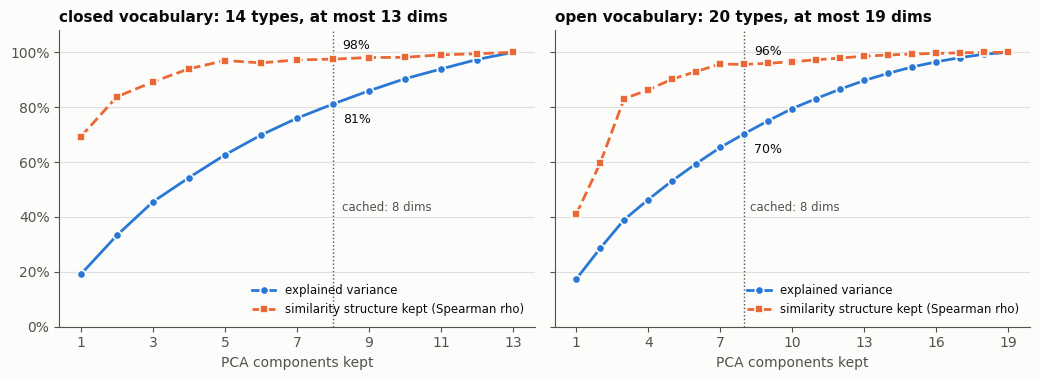

In [13]:
def plot_pca_curves(path):
    """Plot kept variance and kept similarity structure against the number of PCA components, one panel per vocabulary."""
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
    styles = [("variance", SERIES[0], "o", "-", "explained variance"),
              ("similarity_rho", SERIES[1], "s", "--", "similarity structure kept (Spearman rho)")]
    for ax, scheme in zip(axes, SCHEMES):
        t, K = PCA_PRESERVATION[scheme], len(VOCABS[scheme])
        ax.axvline(PCA_DIMS, color=INK_2, lw=1, ls=":", zorder=1)
        for col, color, marker, ls, label in styles:
            ax.plot(t["dims"], t[col], color=color, marker=marker, ls=ls, lw=2, ms=6, mec=SURFACE, mew=1.2, label=label, zorder=3)
            y = t.loc[t["dims"] == PCA_DIMS, col].item()
            ax.annotate(f"{y:.0%}", (PCA_DIMS, y), xytext=(7, -14 if col == "variance" else 7), textcoords="offset points",
                        color=INK, fontsize=9)
        ax.set_title(f"{scheme} vocabulary: {K} types, at most {K - 1} dims")
        ax.set_xlabel("PCA components kept")
        ax.set_xticks(range(1, K, 2 if K < 16 else 3))
        ax.set_ylim(0, 1.08)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
        ax.grid(axis="x", visible=False)
        ax.text(PCA_DIMS + 0.25, 0.42, f"cached: {PCA_DIMS} dims", color=INK_2, fontsize=8.5)
        ax.legend(loc="lower right", fontsize=8.5)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

plot_pca_curves(OUT_DIR / "assay_pca_variance.png")

In [14]:
# ----- test: PCA compression ---------------------------------------------------------------------------------------------
from scipy.spatial.distance import pdist

# cosine_matrix on hand-made vectors: parallel -> 1, orthogonal -> 0, opposite -> -1, scale-invariant
v = np.array([[1, 0], [0, 1], [-1, 0], [2, 0]], dtype=float)
assert np.allclose(cosine_matrix(v), [[1, 0, -1, 1], [0, 1, 0, 0], [-1, 0, 1, -1], [1, 0, -1, 1]])

for scheme in SCHEMES:
    X, K = MATRIX[scheme], len(VOCABS[scheme])
    assert X.shape == (K, EMB_DIM) and list(TABLES[scheme]) == VOCABS[scheme]
    assert np.allclose(X[3], TABLES[scheme][VOCABS[scheme][3]])                 # rows follow the vocabulary order

    # K - 1 components are lossless (K points span at most K - 1 dimensions): re-parametrisation, not compression
    full = PCA(n_components=K - 1, svd_solver="full").fit(X)
    assert np.isclose(full.explained_variance_ratio_.sum(), 1, atol=1e-5), full.explained_variance_ratio_.sum()
    assert np.abs(full.inverse_transform(full.transform(X)) - X).max() < 1e-5

    # the cached compression keeps fewer than K - 1 components
    pca, Z = PCA_MODELS[scheme], np.stack(list(REDUCED[scheme].values()))
    assert pca.n_components_ == PCA_DIMS < K - 1
    assert list(REDUCED[scheme]) == VOCABS[scheme] and Z.shape == (K, PCA_DIMS) and Z.dtype == np.float32
    assert np.abs(Z.mean(axis=0)).max() < 1e-5                                   # PCA centres the table
    assert np.all(np.diff(Z.var(axis=0)) <= 1e-9)                                # components come ordered by variance
    assert np.all(pdist(Z) <= pdist(X) + 1e-5)                                   # an orthogonal projection never stretches distances

    # preservation table: ends at the lossless K - 1 (variance 1, similarity structure identical), variance never decreases
    table = PCA_PRESERVATION[scheme]
    assert list(table.columns) == ["dims", "variance", "similarity_rho"] and PCA_DIMS in set(table["dims"])
    assert table["dims"].iloc[-1] == K - 1 and abs(table["variance"].iloc[-1] - 1) < 1e-5 and abs(table["similarity_rho"].iloc[-1] - 1) < 1e-6
    assert np.all(np.diff(table["variance"]) >= 0)
row = {s: PCA_PRESERVATION[s].set_index("dims").loc[PCA_DIMS] for s in SCHEMES}
print("PCA: OK (" + "; ".join(f"{s}: {PCA_DIMS} of {len(VOCABS[s]) - 1} possible dims keep {row[s]['variance']:.1%} of the variance, "
                              f"similarity rho {row[s]['similarity_rho']:.3f}" for s in SCHEMES) + ")")

PCA: OK (closed: 8 of 13 possible dims keep 81.1% of the variance, similarity rho 0.975; open: 8 of 19 possible dims keep 70.3% of the variance, similarity rho 0.956)


## 5. Cache

Written to `TACKAI_CACHE` (`~/.cache/tackai` unless set in `.env`), next to the other embeddings, with the same naming style and the same `.npz` layout
(`{assay type: vector}`) that `EmbeddingMixin.save` / `.load` use, so they load with the repo's own code.

| file | content |
|---|---|
| `assay_embeddings_vocab={closed14,open20}_model=..._pooling=mean.npz` | pooled 768-d unit vectors, one per assay type |
| `assay_embeddings_vocab=..._pooling=mean_pca8.npz` | the same, compressed to `PCA_DIMS` dimensions |
| `assay_pca_vocab=..._pca8.npz` | the fitted PCA (`mean_`, `components_`, `explained_variance_ratio_`), to project an assay that is not in the table |
| `assay_descriptions.json` | the descriptions, the key -> concept maps, the vocabularies and the settings used (provenance) |

The file names carry the vocabulary size, so a vocabulary that grows when new CSVs are added gets new files instead of silently overwriting old ones.

In [15]:
class AssayEmbedding(EmbeddingMixin):
    """Store for the precomputed assay-type vectors; saves and loads like the other TACK embeddings.

    The vectors are computed in this notebook, so an assay type that is not in the table raises a ``KeyError``
    (use ``embed_assays`` below for assays never seen).
    """

    def _transform_batch(self, keys):
        raise KeyError(f"no cached embedding for {keys}; use embed_assays() for assay types that are not in the table")

DESCRIPTIONS_FILE = "assay_descriptions.json"

def _stem(scheme):
    return f"vocab={scheme}{len(VOCABS[scheme])}_model={MODEL_TAG}_pooling={POOLING}"

CACHE_FILES = {s: {"full": f"assay_embeddings_{_stem(s)}.npz",
                   "pca": f"assay_embeddings_{_stem(s)}_pca{PCA_DIMS}.npz",
                   "pca_model": f"assay_pca_{_stem(s)}_pca{PCA_DIMS}.npz"} for s in SCHEMES}

for s in SCHEMES:
    files = CACHE_FILES[s]
    AssayEmbedding(embeddings=TABLES[s], filename=files["full"], cache_dir=CACHE_DIR).save()
    AssayEmbedding(embeddings=REDUCED[s], filename=files["pca"], cache_dir=CACHE_DIR).save()
    pca = PCA_MODELS[s]
    np.savez(CACHE_DIR / files["pca_model"], mean_=pca.mean_.astype(np.float32), components_=pca.components_.astype(np.float32),
             explained_variance_ratio_=pca.explained_variance_ratio_.astype(np.float32))

meta = {"notebook": "notebooks/assay_embeddings.ipynb", "model": MODEL_NAME,
        "pooling": {"per_description": POOLING, "across_descriptions": "mean of unit vectors, re-normalised"},
        "n_descriptions": N_DESCRIPTIONS, "embedding_dim": EMB_DIM, "pca_dims": PCA_DIMS,
        "source": {"csv_dir": "data/yaochen", "columns": ASSAY_COLUMNS, "files": sorted(raw_df["file"].unique().tolist())},
        "canonizers": {"closed": "canonical_assay", "open": "normalize_assay (missing -> 'unknown')"},
        "vocab": VOCABS, "concept_of": CONCEPT_OF, "descriptions": ASSAY_DESCRIPTIONS, "files": CACHE_FILES}
(CACHE_DIR / DESCRIPTIONS_FILE).write_text(json.dumps(meta, indent=1, ensure_ascii=False))

for name in [DESCRIPTIONS_FILE] + [f for s in SCHEMES for f in CACHE_FILES[s].values()]:
    print(f"{(CACHE_DIR / name).stat().st_size / 1024:8.1f} KB  {name}")

    12.2 KB  assay_descriptions.json
    45.5 KB  assay_embeddings_vocab=closed14_model=all-mpnet-base-v1_pooling=mean.npz
     3.9 KB  assay_embeddings_vocab=closed14_model=all-mpnet-base-v1_pooling=mean_pca8.npz
    27.8 KB  assay_pca_vocab=closed14_model=all-mpnet-base-v1_pooling=mean_pca8.npz
    65.2 KB  assay_embeddings_vocab=open20_model=all-mpnet-base-v1_pooling=mean.npz
     5.8 KB  assay_embeddings_vocab=open20_model=all-mpnet-base-v1_pooling=mean_pca8.npz
    27.8 KB  assay_pca_vocab=open20_model=all-mpnet-base-v1_pooling=mean_pca8.npz


In [16]:
# ----- test: cache files -------------------------------------------------------------------------------------------------
for scheme in SCHEMES:
    files = CACHE_FILES[scheme]
    assert all((CACHE_DIR / f).is_file() and (CACHE_DIR / f).stat().st_size > 0 for f in files.values()), files
    assert files["full"].startswith("assay_embeddings_vocab=") and f"{scheme}{len(VOCABS[scheme])}" in files["full"]

    # round trip through the repo's own loader: same keys in the same order, bit-identical vectors
    full = AssayEmbedding(load_from_cache=True, filename=files["full"], cache_dir=CACHE_DIR)
    assert list(full.embeddings) == VOCABS[scheme]
    assert all(np.array_equal(full[k], TABLES[scheme][k]) for k in VOCABS[scheme])
    assert full.shape() == (EMB_DIM,)
    reduced = AssayEmbedding(load_from_cache=True, filename=files["pca"], cache_dir=CACHE_DIR)
    assert list(reduced.embeddings) == VOCABS[scheme] and reduced.shape() == (PCA_DIMS,)
    assert all(np.array_equal(reduced[k], REDUCED[scheme][k]) for k in VOCABS[scheme])

    # the saved PCA reproduces the cached compression from the saved full vectors alone
    side = np.load(CACHE_DIR / files["pca_model"])
    assert set(side.files) == {"mean_", "components_", "explained_variance_ratio_"}
    projected = (np.stack(list(full.embeddings.values())) - side["mean_"]) @ side["components_"].T
    assert np.allclose(projected, np.stack(list(reduced.embeddings.values())), atol=1e-5)

# a type that is not cached raises instead of silently inventing a vector
try:
    full.transform(["not a cached assay"])
    raise AssertionError("an uncached assay type was accepted")
except KeyError:
    pass

meta = json.loads((CACHE_DIR / DESCRIPTIONS_FILE).read_text())
assert meta["descriptions"] == ASSAY_DESCRIPTIONS and meta["concept_of"] == CONCEPT_OF and meta["vocab"] == VOCABS
assert meta["model"] == MODEL_NAME and meta["n_descriptions"] == N_DESCRIPTIONS and meta["pca_dims"] == PCA_DIMS
assert meta["files"] == CACHE_FILES
print(f"cache: OK ({sum(len(f) for f in CACHE_FILES.values()) + 1} files in {CACHE_DIR})")

cache: OK (7 files in /Users/ribes/.cache/tackai)


## 6. Looking up an assay, with a fallback

`embed_assays(raws, scheme, reduced)` is the function a feature pipeline calls with raw assay strings (a column of a CSV):

1. canonise each string with the chosen scheme (missing -> `unknown`);
2. if the canonical type is in the cached table, return its vector;
3. **fallback**: otherwise (only possible in the open scheme, which passes unrecognised text through) embed the type's name on the fly with the same encoder,
   (`FALLBACK_TEMPLATE`, the bare name).

The closed scheme never misses (anything unmatched is `other`). `reduced=True` returns the `PCA_DIMS`-dimensional version, projecting fallback vectors with the same fitted PCA.
The bare name is a deliberate but modest choice. Wrapping it in a descriptive sentence ("X: an assay used to measure the degradation of a target protein") looked more like the cached descriptions, but the shared frame
pulled fallback vectors towards one generic cached description. Two checks, both in the test cell: on spelled-out variants of cached assays (they share words with the descriptions, so this is optimistic) the bare name
hits 6 of 6 and the sentence 3 of 6; on genuinely held-out spellings (section 6.1, no shared content word) both are **weak**: 2 of 9 against 1 of 9, with a chance level of 0.7. A fallback vector is therefore a rough placement,
trustworthy mainly when the name contains recognisable words. Its main merit is that it exists, so the pipeline does not crash on a new assay. Bare-name vectors also have a low cosine to every cached assay when the assay is
unrelated (qPCR, SPR), which at least does not pretend to be a match.

A fallback vector is still weaker than a hand-described one (a name instead of three descriptions): when a new assay type shows up often, add descriptions for it in section 2.

In [17]:
CANONIZERS = {"closed": canonical_assay, "open": normalize_assay}
# The bare canonical name was at least as good as the sentence template on both checks (section 6.1 and the test below); a generic sentence frame adds a
# component shared by all assays that pulls fallback vectors towards whichever cached description is most generic.
FALLBACK_TEMPLATE = "{name}"
DESCRIPTIVE_TEMPLATE = "{name}: an assay used to measure the degradation of a target protein."   # the first template tried; kept for the comparison below

def fallback_vectors(names, scheme, reduced=False, template=FALLBACK_TEMPLATE):
    """Embed canonical assay names that are not in the table (``template`` wraps the name; PCA-projected when ``reduced``)."""
    vecs = encode_texts([template.format(name=n) for n in names])
    return PCA_MODELS[scheme].transform(vecs).astype(np.float32) if reduced else vecs

def embed_assays(raws, scheme="open", reduced=False):
    """Embed raw assay strings: cached vector when the canonical type is in the table, otherwise an on-the-fly fallback.

    Args:
        raws: Iterable of raw assay strings (None / NaN / empty count as ``unknown``).
        scheme: ``"closed"`` (14 fixed types) or ``"open"`` (data-driven types; unseen text is embedded on the fly).
        reduced: Return the ``PCA_DIMS``-dimensional compressed vectors instead of the full ones.

    Returns:
        float32 array of shape (len(raws), embedding_dim) or (len(raws), PCA_DIMS), one row per input, in order.
    """
    if scheme not in CANONIZERS:
        raise ValueError(f"scheme must be one of {sorted(CANONIZERS)}, got {scheme!r}")
    keys = [CANONIZERS[scheme](None if pd.isna(r) else r) for r in raws]   # pd.NA (pandas columns) is missing, not the text '<NA>'
    table = REDUCED[scheme] if reduced else TABLES[scheme]
    misses = sorted({k for k in keys if k not in table})
    fallback = dict(zip(misses, fallback_vectors(misses, scheme, reduced))) if misses else {}
    rows = [table[k] if k in table else fallback[k] for k in keys]
    return np.stack(rows) if rows else np.empty((0, PCA_DIMS if reduced else EMB_DIM), dtype=np.float32)

# what the fallback does with assays that are not in the table: the two closest cached types (cosine to the pooled vectors)
unseen = ["Quantitative PCR of mRNA", "Surface plasmon resonance", "Chemiluminescent protein gel blot",
          "Bioluminescence resonance energy transfer (BRET)"]
for text, vec in zip(unseen, embed_assays(unseen, "open")):
    sims = MATRIX["open"] @ vec
    nearest = ", ".join(f"{VOCABS['open'][i]} ({sims[i]:.2f})" for i in np.argsort(-sims)[:2])
    print(f"{text:52s} -> {nearest}")

Quantitative PCR of mRNA                             -> elisa (0.33), egfp/mcherry reporter assay (0.32)
Surface plasmon resonance                            -> msd (0.26), fluoresyn nanobody biosensor (gfp immunostaining) (0.24)
Chemiluminescent protein gel blot                    -> western blot (0.57), fluorescent reporter (0.56)
Bioluminescence resonance energy transfer (BRET)     -> nanoluc reporter (0.39), fluorescent reporter (0.35)


### 6.1 How good is the fallback?

Spellings of assays that are **not** in the table, each with the cached types that would be a correct answer. None of these strings shares a content word with the descriptions of its targets (checked in the test cell
below), so retrieving the right type is not string matching. `chance` is the expected number of hits for a random guess among the 20 open types.

In [18]:
HELD_OUT_SYNONYMS = {
    "SDS-PAGE and immunodetection": {"western blot", "dot blot"},
    "europium cryptate proximity readout": {"htrf"},
    "antigen capture microtiter quantitation": {"elisa", "elisa + western blot"},
    "bipartite complementation tag": {"hibit", "nanoluc reporter"},
    "hydrodynamic focusing sorter": {"flow cytometry"},
    "dual chromophore normalisation": {"egfp/mcherry reporter assay", "fluorescent reporter"},
    "tetrazolium reduction": {"viability assay"},
    "immunodot assay": {"dot blot"},
    "confocal laser scanning": {"fluorescence imaging", "high-content imaging"},
}

def retrieval_hits(synonyms, template):
    """How many spellings have a correct cached type as the nearest pooled vector (cosine) when embedded with ``template``."""
    names = [CANONIZERS["open"](s) for s in synonyms]                  # what embed_assays would embed for these strings
    top1 = [VOCABS["open"][i] for i in (fallback_vectors(names, "open", template=template) @ MATRIX["open"].T).argmax(1)]
    return sum(t in ok for t, ok in zip(top1, synonyms.values())), top1

chance = sum(len(ok) for ok in HELD_OUT_SYNONYMS.values()) / len(VOCABS["open"])
print(f"{len(HELD_OUT_SYNONYMS)} held-out spellings, chance {chance:.1f} hits")
for label, template in [("bare name", FALLBACK_TEMPLATE), ("descriptive sentence", DESCRIPTIVE_TEMPLATE)]:
    hits, top1 = retrieval_hits(HELD_OUT_SYNONYMS, template)
    print(f"  {label:22s}: {hits}/{len(HELD_OUT_SYNONYMS)} on a correct type")
    if label == "bare name":
        for syn, top in zip(HELD_OUT_SYNONYMS, top1):
            print(f"      {syn:42s} -> {top}")

9 held-out spellings, chance 0.7 hits
  bare name             : 2/9 on a correct type
      SDS-PAGE and immunodetection               -> elisa
      europium cryptate proximity readout        -> msd
      antigen capture microtiter quantitation    -> msd
      bipartite complementation tag              -> incell hunter
      hydrodynamic focusing sorter               -> flow cytometry
      dual chromophore normalisation             -> western blot
      tetrazolium reduction                      -> unknown
      immunodot assay                            -> elisa
      confocal laser scanning                    -> fluorescence imaging


  descriptive sentence  : 1/9 on a correct type


In [19]:
# ----- test: embed_assays ------------------------------------------------------------------------------------------------
raws = [np.nan, "Western Blot", None, "HiBiT", "  western blot ", pd.NA]
for scheme in SCHEMES:
    E = embed_assays(raws, scheme)
    assert E.shape == (len(raws), EMB_DIM) and E.dtype == np.float32
    assert np.array_equal(E[0], TABLES[scheme]["unknown"]) and np.array_equal(E[2], TABLES[scheme]["unknown"])   # missing -> unknown
    assert np.array_equal(E[1], E[4])                                                                          # spelling variants
    assert np.array_equal(E[5], TABLES[scheme]["unknown"])                                                      # pd.NA from pandas columns is missing too, not text
    assert np.array_equal(E[1], TABLES[scheme][CANONIZERS[scheme]("Western Blot")])                            # cached type: stored vector
    Z = embed_assays(raws, scheme, reduced=True)
    assert Z.shape == (len(raws), PCA_DIMS) and Z.dtype == np.float32
    assert np.array_equal(Z[3], REDUCED[scheme][CANONIZERS[scheme]("HiBiT")])

# fallback: the open scheme passes unrecognised text through, so these are true cache misses
novel = ["Quantitative PCR of mRNA", "quantitative  pcr of mrna", "Surface plasmon resonance"]
assert all(CANONIZERS["open"](r) not in TABLES["open"] for r in novel), "test strings must not be cached"
F = embed_assays(novel, "open")
assert F.shape == (3, EMB_DIM) and F.dtype == np.float32 and np.allclose(np.linalg.norm(F, axis=1), 1, atol=1e-5)
assert np.allclose(F[0], F[1], atol=1e-6)            # case / whitespace variants normalise to the same type
assert not np.allclose(F[0], F[2], atol=1e-3)        # different assays get different vectors
Fz = embed_assays(novel, "open", reduced=True)
assert Fz.shape == (3, PCA_DIMS) and Fz.dtype == np.float32 and np.allclose(Fz[0], Fz[1], atol=1e-5)
assert np.allclose(Fz, PCA_MODELS["open"].transform(F), atol=1e-4)   # projected with the same fitted PCA

# hits, misses and missing values mixed in one call keep their order
M = embed_assays(["HiBiT", novel[0], np.nan], "open")
assert np.array_equal(M[0], TABLES["open"]["hibit"]) and np.allclose(M[1], F[0], atol=1e-5) and np.array_equal(M[2], TABLES["open"]["unknown"])

# the closed scheme never misses: anything unmatched is `other`
assert np.array_equal(embed_assays(["Surface plasmon resonance"], "closed")[0], TABLES["closed"]["other"])
assert embed_assays([], "open").shape == (0, EMB_DIM) and embed_assays([], "open", reduced=True).shape == (0, PCA_DIMS)
try:
    embed_assays(["HiBiT"], "bogus")
    raise AssertionError("an unknown scheme was accepted")
except ValueError:
    pass
# fallback sanity check on spelled-out variants of cached assays. They share vocabulary with the descriptions (so this is optimistic, not held out);
# the first template tried ("<name>: an assay used to measure the degradation ...") hit 3 of 6.
spelling_variants = {"TR-FRET immunoassay": {"htrf"}, "electrochemiluminescence immunoassay": {"msd"},
            "enzyme-linked immunosorbent assay": {"elisa", "elisa + western blot"}, "protein gel blotting": {"western blot", "dot blot"},
            "confocal microscopy": {"fluorescence imaging", "high-content imaging"}, "luciferase reporter": {"nanoluc reporter", "hibit"}}
assert all(CANONIZERS["open"](r) not in TABLES["open"] for r in spelling_variants), "variants must be cache misses"

def content_words(text):
    """Lower-case words of 4+ letters, minus words every description shares (assay, protein, cell, target)."""
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if len(w) >= 4} - {"assay", "protein", "cell", "cells", "target"}

def shared_vocabulary(synonym, accepted):
    """Content words a synonym shares with the descriptions of the cached assays it is expected to map to."""
    desc = " ".join(d for key in accepted for d in ASSAY_DESCRIPTIONS[CONCEPT_OF["open"][key]])
    return content_words(synonym) & content_words(desc)

# a 'held-out' synonym must share no content word with the descriptions of its target (otherwise the retrieval is partly string matching)
leaky = {syn: shared_vocabulary(syn, ok) for syn, ok in HELD_OUT_SYNONYMS.items() if shared_vocabulary(syn, ok)}
assert not leaky, f"synonyms that are not held out (shared words): {leaky}"
assert all(CANONIZERS["open"](r) not in TABLES["open"] for r in HELD_OUT_SYNONYMS), "held-out spellings must be cache misses"
bare_hits, _ = retrieval_hits(HELD_OUT_SYNONYMS, FALLBACK_TEMPLATE)
descriptive_hits, _ = retrieval_hits(HELD_OUT_SYNONYMS, DESCRIPTIVE_TEMPLATE)
assert bare_hits >= descriptive_hits, f"the bare name should not do worse than the descriptive template ({bare_hits} vs {descriptive_hits})"
syn_vecs = embed_assays(list(spelling_variants), "open")
syn_top1 = [VOCABS["open"][i] for i in (syn_vecs @ MATRIX["open"].T).argmax(1)]
syn_hits = sum(top in ok for top, ok in zip(syn_top1, spelling_variants.values()))
assert syn_hits >= 5, f"fallback put only {syn_hits}/{len(spelling_variants)} spelled-out variants on the right assay: {dict(zip(spelling_variants, syn_top1))}"
print(f"embed_assays: OK (cache hits exact, missing -> unknown, fallback unit-norm and consistent with the fitted PCA; "
      f"{syn_hits}/{len(spelling_variants)} spelled-out variants and {bare_hits}/{len(HELD_OUT_SYNONYMS)} held-out spellings (descriptive template: {descriptive_hits}) land on a correct assay)")

embed_assays: OK (cache hits exact, missing -> unknown, fallback unit-norm and consistent with the fitted PCA; 6/6 spelled-out variants and 2/9 held-out spellings (descriptive template: 1) land on a correct assay)


## 7. Similarity of the canonical assay types

Cosine similarity between the pooled embeddings of every pair of assay types, one matrix per vocabulary (768-d vectors, i.e. *before* PCA).
Rows and columns are ordered by hierarchical clustering (average linkage on 1 - similarity, optimal leaf order), so assays the encoder considers alike sit next to each other and show up as dark blocks
on the diagonal. The colour scale starts at the lowest off-diagonal similarity (rounded down), not at 0, so differences between assay types are not flattened; the diagonal is 1 by construction.
`n` on the row labels is the number of `Assay` rows with that type across the CSVs (the files overlap, so these are not unique measurements; 0 means the type comes only from `Assay_STD`).

**Reading the result** (executed values):

* The most similar pairs are the ones an assay scientist would pair: Western blot with In-Cell Western (0.78), ELISA with MSD (0.73), high-content imaging with fluorescence imaging (0.72),
  capillary immunoassay with Western blot (0.71), HiBiT with NanoLuc reporter (0.68). In the open vocabulary the closest pair is an assay and its "+ Western blot" combination (in-cell 0.86; ELISA with its combination 0.76).
* **`unknown` is the most isolated type** (0.25-0.47 to every real assay), so a model can tell "assay not reported" from any actual method, which matters because `unknown` is the most common type (60 % of the pooled `Assay` rows, 38 % in `TACKv2.csv`).
  Its nearest neighbour is `other` (0.65): both mean "unspecified".
* Absolute values are inflated (all sentences are technical text about measuring protein degradation, so even unrelated assays reach 0.4-0.5); read the *ordering*, not the numbers.
* The matrices are only as good as the three hand-written sentences per assay (section 2); a wrong or vague description moves an assay in this picture.

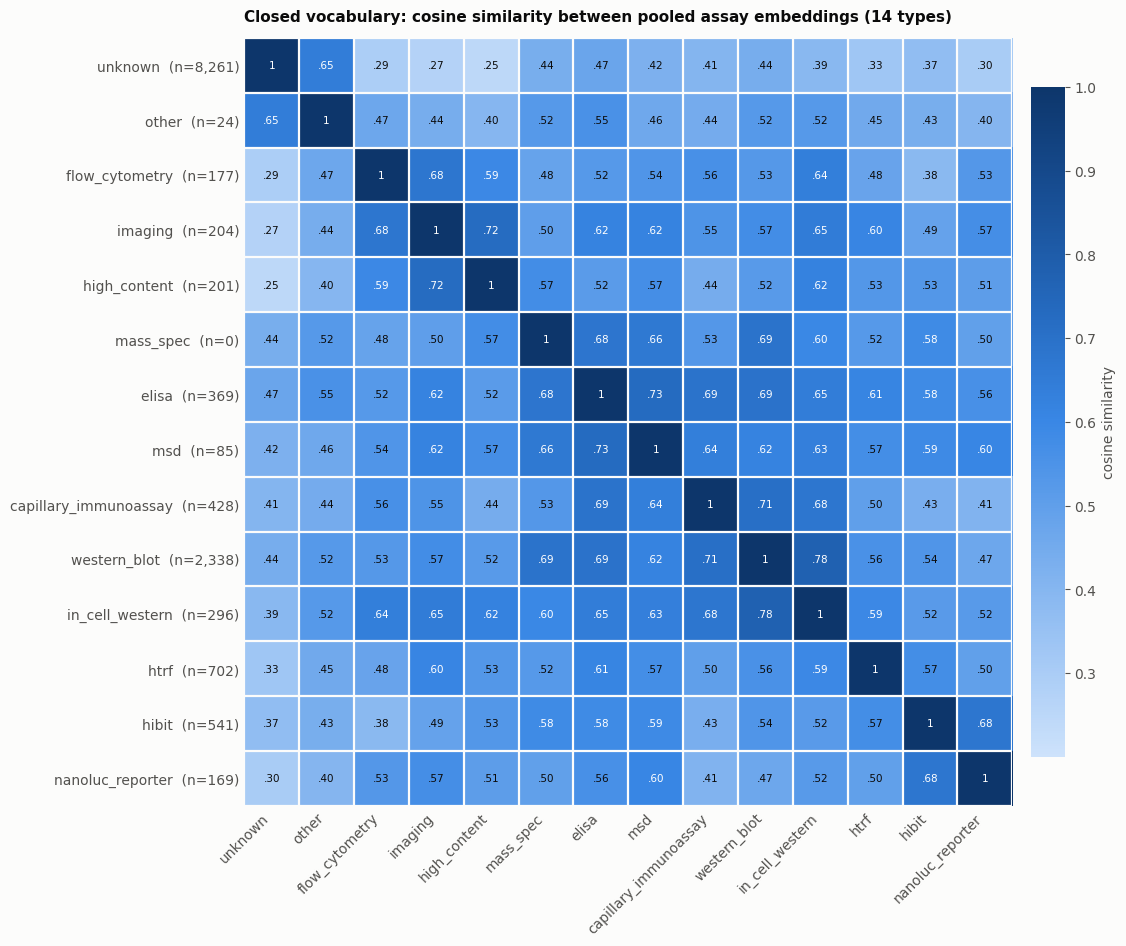

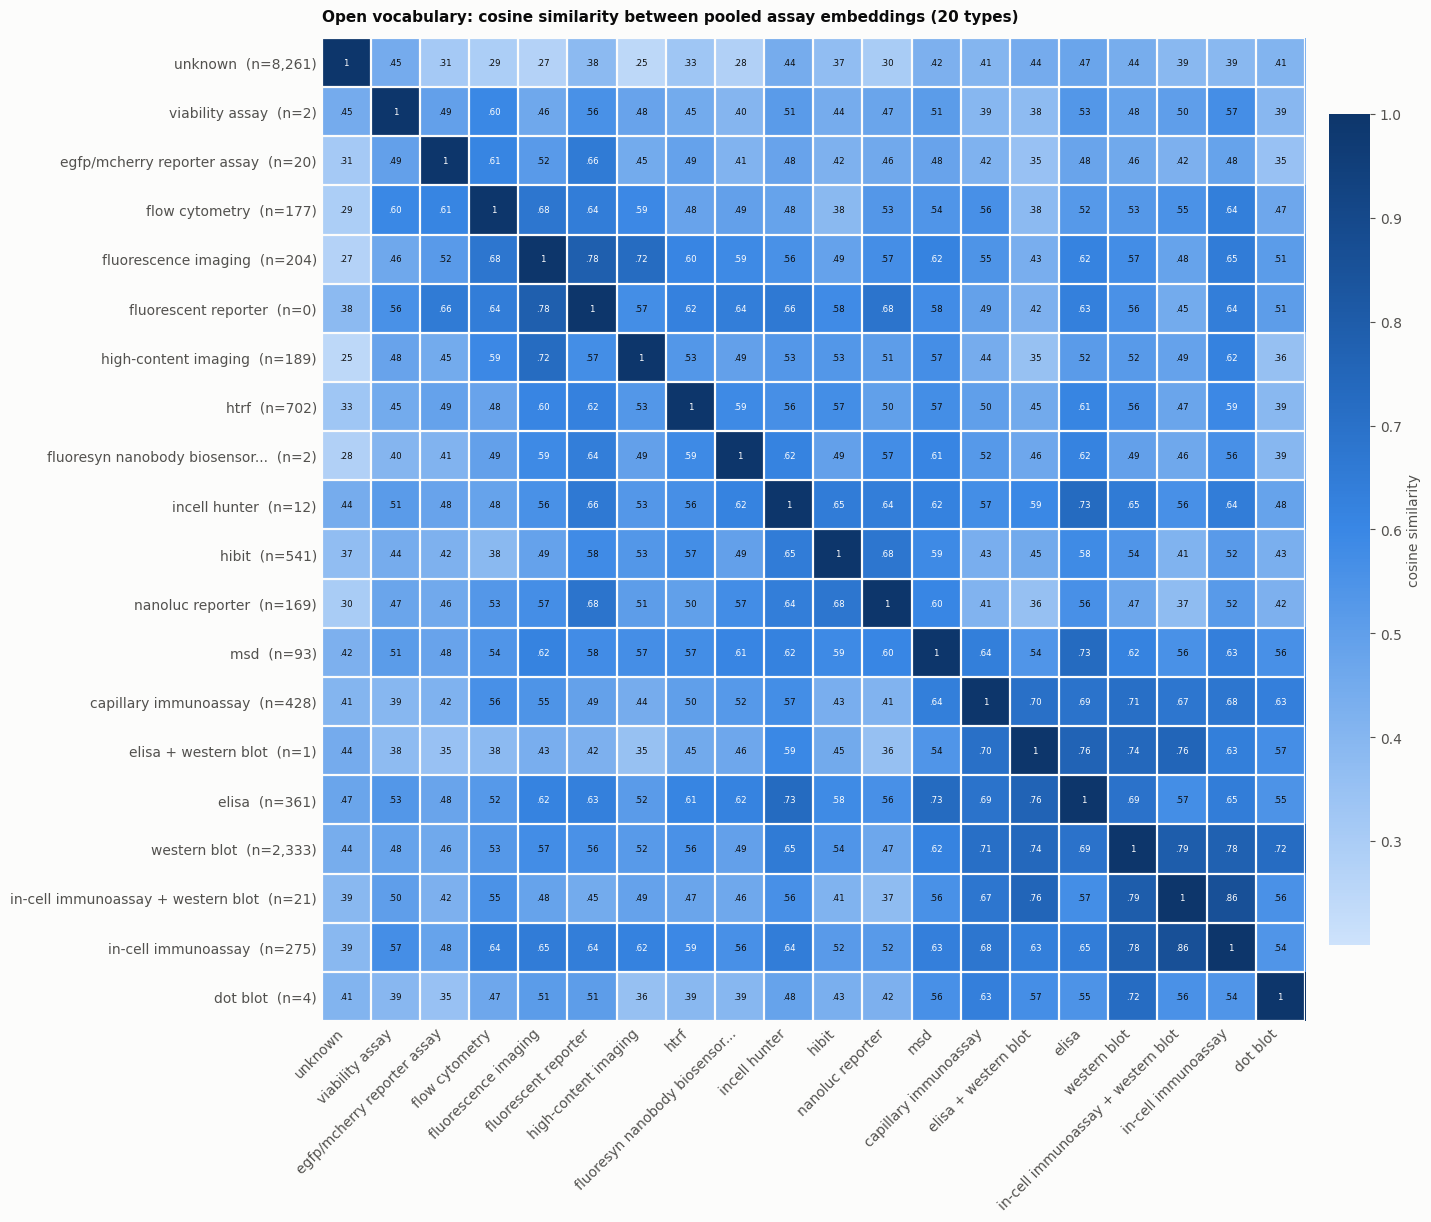

In [20]:
import textwrap

SIMILARITY = {s: cosine_matrix(MATRIX[s]) for s in SCHEMES}

def cluster_order(sim):
    """Row order that puts similar assays next to each other (hierarchical clustering, average linkage, optimal leaf order).

    Args:
        sim: Symmetric similarity matrix, shape (n, n), diagonal 1.

    Returns:
        List with a permutation of ``range(n)``.
    """
    dist = np.clip(1 - sim, 0, None)
    dist = (dist + dist.T) / 2
    np.fill_diagonal(dist, 0)
    condensed = squareform(dist, checks=False)
    tree = linkage(condensed, method="average")
    return list(leaves_list(optimal_leaf_ordering(tree, condensed)))

def plot_similarity(scheme, path):
    """Heatmap of the pairwise cosine similarity between the pooled embeddings of one vocabulary, clustered, with row counts."""
    sim, vocab = SIMILARITY[scheme], VOCABS[scheme]
    K = len(vocab)
    order = cluster_order(sim)
    S = sim[np.ix_(order, order)]
    vmin = np.floor(sim[~np.eye(K, dtype=bool)].min() * 10) / 10        # colour scale starts at the lowest off-diagonal value
    counts = ROW_COUNTS[scheme].reindex(vocab, fill_value=0)
    short = lambda key: textwrap.shorten(key, width=34, placeholder="...")

    side = 0.5 * K + 3.4
    fig, ax = plt.subplots(figsize=(side + 1.2, side * 0.92))
    im = ax.imshow(S, cmap=SEQ_CMAP, vmin=vmin, vmax=1.0)
    ax.set_xticks(range(K), [short(vocab[i]) for i in order], rotation=45, ha="right")
    ax.set_yticks(range(K), [f"{short(vocab[i])}  (n={counts[vocab[i]]:,})" for i in order])
    ax.set_xticks(np.arange(-0.5, K, 1), minor=True)                     # 2 px surface gaps between cells
    ax.set_yticks(np.arange(-0.5, K, 1), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=1.6)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

    fontsize = 7.5 if K <= 14 else 6.2
    for r in range(K):
        for c in range(K):
            v = S[r, c]
            r_, g_, b_, _ = SEQ_CMAP((v - vmin) / (1 - vmin))
            dark_cell = 0.299 * r_ + 0.587 * g_ + 0.114 * b_ < 0.5
            ax.text(c, r, "1" if r == c else f"{v:.2f}"[1:], ha="center", va="center", fontsize=fontsize,
                    color="#ffffff" if dark_cell else INK)
    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cbar.set_label("cosine similarity")
    cbar.outline.set_visible(False)
    ax.set_title(f"{scheme.capitalize()} vocabulary: cosine similarity between pooled assay embeddings ({K} types)", loc="left", pad=12)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()

for scheme in SCHEMES:
    plot_similarity(scheme, OUT_DIR / f"assay_similarity_{scheme}.png")

In [21]:
# ----- test: similarity matrices -----------------------------------------------------------------------------------------
# cluster_order on a planted example: (0, 1) and (2, 3) are the close pairs, so each pair must end up adjacent
S4 = np.array([[1, .9, .1, .2], [.9, 1, .15, .1], [.1, .15, 1, .8], [.2, .1, .8, 1]])
order4 = list(cluster_order(S4))
assert sorted(order4) == [0, 1, 2, 3]
pos = {i: p for p, i in enumerate(order4)}
assert abs(pos[0] - pos[1]) == 1 and abs(pos[2] - pos[3]) == 1, order4

for scheme in SCHEMES:
    S, K = SIMILARITY[scheme], len(VOCABS[scheme])
    assert S.shape == (K, K) and np.allclose(S, S.T, atol=1e-6) and np.allclose(np.diag(S), 1, atol=1e-5)
    assert S.min() > -1 and S.max() <= 1 + 1e-6
    assert S[~np.eye(K, dtype=bool)].max() < 0.999, "two assay types share (almost) the same vector"
    assert sorted(cluster_order(S)) == list(range(K))
    assert (OUT_DIR / f"assay_similarity_{scheme}.png").stat().st_size > 10_000

# pairs fixed before looking at the matrices: related assays are more similar than unrelated ones
def sim_of(scheme, a, b):
    return SIMILARITY[scheme][VOCABS[scheme].index(a), VOCABS[scheme].index(b)]
related = [("closed", "hibit", "nanoluc_reporter", "mass_spec"),
           ("closed", "western_blot", "capillary_immunoassay", "flow_cytometry"),
           ("closed", "high_content", "imaging", "elisa"),
           ("open", "elisa", "elisa + western blot", "flow cytometry"),
           ("open", "in-cell immunoassay", "in-cell immunoassay + western blot", "unknown")]
for scheme, a, b, unrelated in related:
    assert sim_of(scheme, a, b) > sim_of(scheme, a, unrelated), (scheme, a, b, unrelated, sim_of(scheme, a, b), sim_of(scheme, a, unrelated))
print(f"similarity matrices: OK ({len(related)} related-vs-unrelated pairs ordered as expected; figures in {OUT_DIR.name}/)")

similarity matrices: OK (5 related-vs-unrelated pairs ordered as expected; figures in assay_embedding_results/)


## 8. Summary and how to use the cache

Cached in `TACKAI_CACHE` (section 5), keyed by canonical assay type:

* **closed vocabulary** (14 types, fixed): drop-in semantic replacement for the one-hot `assay` block of `fusion_comparison.ipynb`;
* **open vocabulary** (finer, data-driven): separates reporter, biosensor, viability and combination assays that the closed one lumps into `other` / its neighbours;
* each as the full 768-d unit vector and as `PCA_DIMS` PCA components, plus the fitted PCA and the descriptions (`assay_descriptions.json`).

A pipeline needs only `numpy` and the canonisation function of its chosen scheme (copy `canonical_assay` or `normalize_assay` from section 1):

```python
table = dict(np.load(Path(get_cache_dir()) / "assay_embeddings_vocab=closed14_model=all-mpnet-base-v1_pooling=mean_pca8.npz"))
X_assay = np.stack([table[canonical_assay(None if pd.isna(a) else a)] for a in df["Assay"]])   # (n_rows, 8); missing -> the `unknown` vector
```

The `pd.isna` guard matters: `canonical_assay` recognises `None` and NaN but not `pd.NA` (what a pandas `string` column holds for missing values), which it would silently file under `other`.
`embed_assays` applies the guard for you.

Things to decide when this goes into a model:

* the compressed vectors are PCA-centred, the full ones are unit vectors; scale them like any other feature block;
* the PCA is fitted on the vocabulary table only (no labels, no data rows), so it cannot leak across CV folds;
* if a CSV adds an assay type the open rules do not know, `embed_assays` still returns a vector (a rough bare-name fallback, section 6), and the vocabulary check in section 2 tells you which descriptions to write.

In [ ]:
# the cache as a downstream pipeline uses it (plain numpy, no notebook objects), on the real TACKv2 rows
tack_assay = pd.read_csv(DATA_DIR / "TACKv2.csv", usecols=["Assay"], dtype={"Assay": "string"})["Assay"]   # string dtype: missing values are pd.NA
for scheme in SCHEMES:
    table = dict(np.load(CACHE_DIR / CACHE_FILES[scheme]["pca"]))
    keys = [CANONIZERS[scheme](None if pd.isna(a) else a) for a in tack_assay]   # the pd.isna guard: pd.NA is missing, not text
    X = np.stack([table[k] for k in keys])                          # a KeyError here would mean a type without a cached vector
    assert X.shape == (len(tack_assay), PCA_DIMS)
    assert np.array_equal(X, embed_assays(tack_assay, scheme, reduced=True))
    print(f"{scheme}: {len(tack_assay):,} TACKv2 rows -> feature matrix {X.shape}; {len(set(keys))} distinct types, all found in the cache "
          f"({np.mean([k == 'unknown' for k in keys]):.0%} of the rows are unknown)")

NameError: name 'REDUCED' is not defined

In [19]:
POOLING = "mean"
CANONIZERS = {"closed": canonical_assay, "open": normalize_assay}

def embed_assays(raws, scheme="open", reduced=False):
    """Embed raw assay strings: cached vector when the canonical type is in the table, otherwise an on-the-fly fallback.

    Args:
        raws: Iterable of raw assay strings (None / NaN / empty count as ``unknown``).
        scheme: ``"closed"`` (14 fixed types) or ``"open"`` (data-driven types; unseen text is embedded on the fly).
        reduced: Return the ``PCA_DIMS``-dimensional compressed vectors instead of the full ones.

    Returns:
        float32 array of shape (len(raws), embedding_dim) or (len(raws), PCA_DIMS), one row per input, in order.
    """
    if scheme not in CANONIZERS:
        raise ValueError(f"scheme must be one of {sorted(CANONIZERS)}, got {scheme!r}")
    keys = [CANONIZERS[scheme](None if pd.isna(r) else r) for r in raws]   # pd.NA (pandas columns) is missing, not the text '<NA>'
    table = REDUCED[scheme] if reduced else TABLES[scheme]
    misses = sorted({k for k in keys if k not in table})
    fallback = dict(zip(misses, fallback_vectors(misses, scheme, reduced))) if misses else {}
    rows = [table[k] if k in table else fallback[k] for k in keys]
    return np.stack(rows) if rows else np.empty((0, PCA_DIMS if reduced else EMB_DIM), dtype=np.float32)

def _stem(scheme):
    return f"vocab={scheme}{len(VOCABS[scheme])}_model={MODEL_TAG}_pooling={POOLING}"

CACHE_FILES = {s: {"full": f"assay_embeddings_{_stem(s)}.npz",
                   "pca": f"assay_embeddings_{_stem(s)}_pca{PCA_DIMS}.npz",
                   "pca_model": f"assay_pca_{_stem(s)}_pca{PCA_DIMS}.npz"} for s in SCHEMES}

# the cache as a downstream pipeline uses it (plain numpy, no notebook objects), on the real TACKv2 rows
tack_assay = pd.read_csv(DATA_DIR / "TACKv2.csv", usecols=["Assay"], dtype={"Assay": "string"})["Assay"]   # string dtype: missing values are pd.NA
for scheme in SCHEMES:
    table = dict(np.load(CACHE_DIR / CACHE_FILES[scheme]["pca"]))
    for k, v in table.items():
        assert v.shape == (PCA_DIMS,) and v.dtype == np.float32, f"{scheme}: {k} -> {v.shape}, {v.dtype}"
        print(f"{scheme}: {k} -> {v.shape}, {v.dtype}")

    keys = [CANONIZERS[scheme](None if pd.isna(a) else a) for a in tack_assay]   # the pd.isna guard: pd.NA is missing, not text
    X = np.stack([table[k] for k in keys])                          # a KeyError here would mean a type without a cached vector
    assert X.shape == (len(tack_assay), PCA_DIMS)
    print('-' * 80)
    print(f"{scheme}: {len(tack_assay):,} TACKv2 rows -> feature matrix {X.shape}; {len(set(keys))} distinct types, all found in the cache "
          f"({np.mean([k == 'unknown' for k in keys]):.0%} of the rows are unknown)")
    print('-' * 80)

closed: western_blot -> (8,), float32
closed: in_cell_western -> (8,), float32
closed: capillary_immunoassay -> (8,), float32
closed: hibit -> (8,), float32
closed: nanoluc_reporter -> (8,), float32
closed: htrf -> (8,), float32
closed: elisa -> (8,), float32
closed: msd -> (8,), float32
closed: flow_cytometry -> (8,), float32
closed: high_content -> (8,), float32
closed: imaging -> (8,), float32
closed: mass_spec -> (8,), float32
closed: other -> (8,), float32
closed: unknown -> (8,), float32
--------------------------------------------------------------------------------
closed: 6,214 TACKv2 rows -> feature matrix (6214, 8); 13 distinct types, all found in the cache (38% of the rows are unknown)
--------------------------------------------------------------------------------
open: western blot -> (8,), float32
open: htrf -> (8,), float32
open: hibit -> (8,), float32
open: capillary immunoassay -> (8,), float32
open: elisa -> (8,), float32
open: in-cell immunoassay -> (8,), float32
op